# Markov switching com trend following – ações americanas

- Estratégia de trend following com o sinal de time series momentum (MOSKOWITZ; OOI; PEDERSEN, 2012), filtrada por um modelo de Markov switching estimado pelo filtro de Hamilton (HAMILTON, 1989): a posição só é mantida quando o modelo indica regime de baixa volatilidade, já que as perdas do momentum se concentram em períodos de alta volatilidade (DANIEL; MOSKOWITZ, 2016).

- Primeiramente escolhemos as ações americanas com melhor relação entre drift e volatilidade, o que favorece a identificação de tendências (SHI; LIAN, 2025).

- Para evitar look-ahead bias, usamos dados de jul/2001 a jun/2021 para treino e de jul/2021 a jun/2026 como teste. No teste, o modelo é reestimado a cada 12 meses (todo 1º de julho), usando sempre os 20 anos anteriores.

In [1]:
import numpy as np
import pandas as pd
import yfinance as yf

# Grandes empresas americanas com histórico desde 2001 (tickers atuais no Yahoo).

tickers = [
    "AAPL", "MSFT", "AMZN", "JPM", "BAC", "WFC", "JNJ", "PFE", "MRK", "UNH",
    "PG", "KO", "PEP", "WMT", "HD", "MCD", "NKE", "DIS", "XOM", "CVX",
    "INTC", "CSCO", "ORCL", "IBM", "CAT", "BA", "MMM", "GE", "T", "VZ",
]


train_start = "2001-07-01" 
train_end   = "2021-06-30"
test_start  = "2021-07-01"   
test_end    = "2026-06-30"
JANELA_ANOS = 20        # anos usados em cada reestimação (janela móvel)

# Só o período de treino (end do yfinance é exclusivo → test_start inclui até 30/06/2021)
dados = yf.download(tickers, start=train_start, end=test_start, auto_adjust=True, progress=False)
# Dias com volume zero são preço repetido pelo Yahoo (sem negociação real) → tratados como faltantes.
precos = dados["Close"].where(dados["Volume"] > 0)

# Remove ações sem histórico suficiente (exige 90% dos dias com negociação)
cobertura = precos.notna().mean()
removidas = cobertura[cobertura < 0.9].index.tolist()
if removidas:
    print("Removidas por falta de dados:", removidas)
precos = precos.drop(columns=removidas)

# Drift e volatilidade anualizados (retornos log)
retornos = np.log(precos).diff()
drift = retornos.mean() * 252
vol = retornos.std() * np.sqrt(252)

ranking = pd.DataFrame({"drift": drift, "vol": vol, "mu/sigma": drift / vol})
ranking = ranking.sort_values("mu/sigma", ascending=False)

selecionados = ranking.head(3).index.tolist()
display(ranking)
print("Selecionados:", selecionados)

,drift,vol,mu/sigma
Ticker,,,
AAPL,0.296694,0.355047,0.835646
NKE,0.180281,0.277142,0.650503
AMZN,0.273896,0.438461,0.624676
MCD,0.133051,0.224896,0.591611
UNH,0.171505,0.310384,0.552556
PG,0.098921,0.183656,0.538621
JNJ,0.084971,0.185242,0.458703
MSFT,0.124951,0.282579,0.442181
PEP,0.084768,0.192286,0.440842


Selecionados: ['AAPL', 'NKE', 'AMZN']


# Ações selecionadas
- O trend following identifica tendências mais facilmente em ativos com drift maior e volatilidade menor (SHI; LIAN, 2025, p. 6). Por isso, escolhemos as 3 ações de maior μ/σ no treino (ver `Selecionados` acima).
- O ranking usa μ/σ com sinal, ou seja, favorece ativos com tendência de alta. Shi e Lian (2025) observam que, para estratégias que também vendem a descoberto, o valor absoluto do índice é o mais relevante; aqui priorizamos o lado comprado.
- Dias com volume zero foram tratados como sem negociação: o Yahoo repete o último preço nesses dias, o que gera retornos zero artificiais.
- Taxa livre de risco: T-Bill de 3 meses (^IRX no Yahoo), no lugar do CDI.

In [2]:
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

tickers = selecionados

# end do yfinance é exclusivo → dia seguinte ao fim do teste
fim_download = (pd.Timestamp(test_end) + pd.Timedelta(days=1)).strftime("%Y-%m-%d")

prices = {}
for ticker in tickers:
    prices[ticker] = yf.download(ticker, start=train_start, end=fim_download,
                                 interval="1d", auto_adjust=True, progress=False)
    prices[ticker] = prices[ticker].droplevel(1, axis=1)
    # remove dias sem negociação (retorno zero artificial distorce o Markov switching)
    prices[ticker] = prices[ticker][prices[ticker]["Volume"] > 0]

# Taxa livre de risco: T-Bill de 3 meses (^IRX, em % a.a.)
irx = yf.download("^IRX", start=train_start, end=fim_download, interval="1d",
                  auto_adjust=False, progress=False)["Close"].squeeze().dropna()
rf_anual = irx / 100
rf_dia = (1 + rf_anual) ** (1 / 252) - 1

RF = 100 * rf_anual.loc[test_start:test_end].mean()   # média do período de teste (% a.a.), usada no Sharpe
print(f"T-Bill médio no teste: {RF:.2f}% a.a.")

T-Bill médio no teste: 3.57% a.a.


# Modelo de Markov switching
- Dois regimes, estimados por máxima verossimilhança com o filtro de Hamilton (1989): a log-verossimilhança é obtida como subproduto do filtro e maximizada numericamente. O filtro começa pela probabilidade incondicional do regime, $\pi = (1-q)/(2-p-q)$, como em Hamilton.
- Especificação: $y_t = \mu + \sigma_{s_t}\,\varepsilon_t$, com $\varepsilon_t$ seguindo uma t de Student. O regime 1 é o de alta volatilidade ($\sigma_1 > \sigma_0$ por construção).
- Diferenças em relação a Hamilton (1989), que usa média dependente do regime, AR(4) e inovações normais:
  - **a volatilidade muda com o regime e a média é única.** Hamilton (1989, p. 369) observa que o filtro continua válido com $\sigma$ dependente do regime, e Ang e Timmermann (2012) mostram que, em ações, os regimes são identificados principalmente pela volatilidade, com diferença pequena entre as médias;
  - **t de Student no lugar da normal**, para acomodar as caudas grossas dos retornos diários;
  - **sem termos autorregressivos.**
- Usamos a probabilidade **filtrada** $\xi_t = P(s_t = 1 \mid y_1, \dots, y_t)$, que só depende de dados até o dia $t$ e, portanto, não tem look-ahead.

In [3]:
from scipy.optimize import minimize
from scipy.special import gammaln


class MarkovSwitching:

    nomes = ["p", "q", "mu", "sigma0", "sigma1", "nu"]

    def __init__(self):
        self.params_ = None
        self.res_ = None

    @staticmethod
    def hamilton_filter(y, p, q, mu, sigma0, sigma1, nu=np.inf):
        # Converte em array a serie de retornos 
        y = np.asarray(y, dtype=float)
        # tamanho do array 
        T = len(y)

        # Modelo: y_t = mu + sigma_{s_t} * eps_t   (média única, volatilidade depende do regime)
        # Isola o choque em cada regime: eps = (y - mu) / sigma_s
        eps0 = (y - mu) / sigma0
        eps1 = (y - mu) / sigma1

        # Log-densidade do retorno dado o regime: log f(y | s) = log g(eps) - log sigma_s,
        # onde g é a densidade da t de Student padrão (escrita à mão: muito mais rápida que scipy)
        def log_t(eps, sigma):
            return (gammaln((nu + 1) / 2) - gammaln(nu / 2) - 0.5 * np.log(nu * np.pi)
                    - np.log(sigma) - (nu + 1) / 2 * np.log1p(eps ** 2 / nu))
        l0 = log_t(eps0, sigma0)
        l1 = log_t(eps1, sigma1)

        # Escala: divide as duas densidades do dia pela maior delas (soma m de volta no log).
        # Evita que f0 e f1 virem 0 ao mesmo tempo (dens = 0 → log = -inf, xi = 0/0).
        m = np.maximum(l0, l1)
        f0 = np.exp(l0 - m).tolist()   # listas: o loop em Python fica bem mais rápido
        f1 = np.exp(l1 - m).tolist()

        # xi irá ter a probabilidade de cada dia estar no regime 1
        xi = [0.0] * T
        # densidade (escalada) de cada dia, para a log-verossimilhança
        dens_dia = [0.0] * T
        
        # Probabilidade incondicional (estacionária) do regime 1:
        # pi = (1 - q) / (2 - p - q)
        xi_prev = (1 - q) / (2 - p - q)
        
        # Percorre os dias em ordem (cada dia depende do anterior) 
        for t in range(T):
            # Step 1: previsão de P(regime 1) antes de ver y_t
            #  s_t = (1 - q) + lambda * s_{t-1} + v_t,   com lambda = p + q - 1
            
            # Abrindo, com xi_prev = P(s_{t-1} = 1 | y_{t-1}, ...):
            #     (1 - q) + (p + q - 1) * xi_prev
            #   = p * xi_prev + (1 - q) * (1 - xi_prev)
            prior1 = p * xi_prev + (1 - q) * (1 - xi_prev)
            
            # Step 2 (parte B): densidade conjunta de y_t e regime 1
            num1 = f1[t] * prior1
            
            # Step 3: densidade total de y_t, somando os dois regimes
            dens = num1 + f0[t] * (1 - prior1)
            
            # Step 4: Bayes, P(regime 1 | y_t)
            xi[t] = num1 / dens

            # guarda a densidade do dia para a log-verossimilhança
            dens_dia[t] = dens
            
            # o xi de hoje vira o "ontem" do próximo dia
            xi_prev = xi[t]

        # log-verossimilhança = soma de log(dens) + o fator de escala m de cada dia
        loglik = m.sum() + np.log(dens_dia).sum()
        return np.array(xi), loglik

    @staticmethod
    def unpack(theta):
        # limita theta para o exp não estourar quando o otimizador explora valores extremos
        theta = np.clip(theta, -20, 20)
        # clip evita p = q = 1 exatos (0/0 em pi quando o sigmoide satura)
        p = np.clip(1 / (1 + np.exp(-theta[0])), 1e-6, 1 - 1e-6)
        q = np.clip(1 / (1 + np.exp(-theta[1])), 1e-6, 1 - 1e-6)
        mu = theta[2]
        sigma0 = np.exp(theta[3])
        sigma1 = sigma0 * (1 + np.exp(theta[4]))   # garante sigma1 > sigma0 (regime 1 = alta vol)
        nu = 2 + np.exp(theta[5])
        return p, q, mu, sigma0, sigma1, nu

    def neg_loglik(self, theta, y):
        ll = self.hamilton_filter(y, *self.unpack(theta))[1]
        # penaliza parâmetros que geram NaN/inf, para o otimizador fugir dessa região
        return -ll if np.isfinite(ll) else 1e10

    def fit(self, y):
        y = np.asarray(y, dtype=float)
        s = y.std()
        theta0 = np.array([3.0, 3.0, y.mean(), np.log(0.7 * s), 0.0, np.log(3.0)])
        self.res_ = minimize(self.neg_loglik, theta0, args=(y,), method="Nelder-Mead",
                             options={"maxiter": 10000, "xatol": 1e-6, "fatol": 1e-6})
        self.params_ = dict(zip(self.nomes, self.unpack(self.res_.x)))
        return self

    def filter(self, y):
        xi, _ = self.hamilton_filter(y, **self.params_)
        return pd.Series(xi, index=y.index)

In [4]:
params_all = {}
regimes = {}

for ticker in tickers:
    close = prices[ticker]["Close"]
    r = 100 * np.log(close).diff().dropna()   # retorno log em %, como no Hamilton

    # Primeira janela (train_start → train_end): usada na tabela e nos gráficos do treino
    modelo = MarkovSwitching().fit(r[train_start:train_end])
    params_all[ticker] = modelo.params_
    xi_treino = modelo.filter(r[train_start:train_end])

    # Teste: a cada 12 meses (jul → jun), reestima com os JANELA_ANOS anos anteriores
    # e filtra só aquele bloco
    xi_teste = []
    ini_bloco = pd.Timestamp(test_start)
    fim_teste = pd.Timestamp(test_end)
    while ini_bloco <= fim_teste:
        fim_bloco = min(ini_bloco + pd.DateOffset(years=1) - pd.Timedelta(days=1), fim_teste)
        ini_est = ini_bloco - pd.DateOffset(years=JANELA_ANOS)
        fim_est = ini_bloco - pd.Timedelta(days=1)

        modelo_bloco = MarkovSwitching().fit(r[ini_est:fim_est])
        # filtra desde o início da janela (para ter o estado inicial certo) e guarda só o bloco
        xi_bloco = modelo_bloco.filter(r[ini_est:fim_bloco]).loc[ini_bloco:fim_bloco]
        xi_teste.append(xi_bloco)

        ini_bloco = fim_bloco + pd.Timedelta(days=1)

    xi = pd.concat([xi_treino] + xi_teste)
    assert xi.index.is_unique, f"{ticker}: datas duplicadas entre treino e teste"
    regimes[ticker] = pd.DataFrame({"ret": r, "xi": xi}).loc[train_start:]

# Tabela de parâmetros (primeira janela) + métricas da Seção 2
tab = pd.DataFrame(params_all).T
tab["pi"] = (1 - tab["q"]) / (2 - tab["p"] - tab["q"])
tab["dur_alta"] = 1 / (1 - tab["p"])      # dias
tab["dur_baixa"] = 1 / (1 - tab["q"])
tab["lambda"] = tab["p"] + tab["q"] - 1
tab.round(4)

,p,q,mu,sigma0,sigma1,nu,pi,dur_alta,dur_baixa,lambda
AAPL,0.9897,0.9898,0.1548,1.0869,2.2371,5.1952,0.4977,97.3177,98.1990,0.9795
NKE,0.9801,0.9939,0.0699,0.9396,2.1018,4.4408,0.2336,50.2030,164.7348,0.9740
AMZN,0.9864,0.9917,0.1022,1.1985,2.6777,3.9952,0.3779,73.4868,120.9970,0.9781


# Estratégias
- **TSMOM** (MOSKOWITZ; OOI; PEDERSEN, 2012): sinal do retorno **em excesso** ao T-Bill nos últimos 252 dias. Comprado se positivo, vendido se negativo.
- **RegimeTSMOM**: mesmo sinal, mas zera a posição quando $\xi_t \geq 0{,}5$ (regime de alta volatilidade). A motivação vem de Daniel e Moskowitz (2016), que mostram que os crashes de momentum ocorrem em estados de alta volatilidade. Eles estudam momentum cross-sectional, definem o estado pelo mercado e usam pesos contínuos; aqui o regime é o de cada ação e o filtro é do tipo liga/desliga.
- **Buy and hold**: referência passiva, comprada desde o primeiro dia.
- Simplificações em relação a Moskowitz, Ooi e Pedersen (2012):
  - cada ação recebe 1/3 do patrimônio na entrada, sem dimensionar a posição pela volatilidade (eles usam 40%/σ);
  - o sinal é verificado diariamente e a posição só muda quando o sinal muda, sem holding fixo de 1 mês nem rebalanceamento mensal.
- O caixa rende T-Bill diariamente. Custo de 0,0325% sobre o valor de cada execução e execução no preço de fechamento.

In [5]:
import backtrader as bt


LOOKBACK = 252   # janela do sinal de tendência (TSMOM)


# Criando uma conta que rentabiliza a T-Bill diariamente (só sobre o capital próprio):
class CarryBroker(bt.brokers.BackBroker):
    params = dict(carry=RF/100)

    def __init__(self):
        super().__init__()

    def next(self):
        super().next()   # executa primeiro as ordens do dia, depois rende o caixa que sobrou
        daily_carry = (1 + self.p.carry) ** (1/252) - 1
        base = max(min(self.cash, self.getvalue()), 0)
        self.cash += base * daily_carry


class PandasXi(bt.feeds.PandasData):
    lines = ("xi", "mom", "rf")
    params = (("xi", -1), ("mom", -1), ("rf", -1))


def make_data(ticker, inicio=test_start, fim=None):
    df = prices[ticker][["Open", "High", "Low", "Close", "Volume"]].copy()
    df["xi"] = regimes[ticker]["xi"].reindex(df.index).ffill()
    # TSMOM (Moskowitz, Ooi e Pedersen, 2012): sinal do retorno EM EXCESSO à taxa livre de risco
    # nos últimos LOOKBACK dias. Índice acumulado da taxa (T-Bill) alinhado às datas da ação,
    # para o retorno da taxa cobrir exatamente o mesmo intervalo do retorno da ação.
    indice_rf = (1 + rf_dia).cumprod().reindex(df.index, method="ffill")
    ret_acao = np.log(df["Close"]).diff(LOOKBACK)
    ret_rf = np.log(indice_rf).diff(LOOKBACK)
    df["mom"] = np.sign(ret_acao - ret_rf)
    df["rf"] = rf_anual.reindex(df.index).ffill()
    df = df.loc[inicio:fim].dropna()
    return PandasXi(dataname=df, name=ticker)


class RegimeTSMOM(bt.Strategy):

    params = dict(thresh=0.5, alloc=0.99)

    def __init__(self):
        self.alvo = {d: None for d in self.datas}

    def next(self):
        self.broker.p.carry = self.datas[0].rf[0]   # atualiza a taxa do dia no broker

        peso = self.p.alloc / len(self.datas)
        for d in self.datas:
            alvo = d.mom[0] * peso if d.xi[0] < self.p.thresh else 0.0
            if alvo != self.alvo[d]:
                self.order_target_percent(data=d, target=alvo)
                self.alvo[d] = alvo


class TSMOM(RegimeTSMOM):
    params = dict(thresh=1.01)   # filtro desligado: segue sempre o sinal de tendência


class BuyHold(bt.Strategy):

    params = dict(alloc=0.99)

    def __init__(self):
        self.comprou = False

    def next(self):
        self.broker.p.carry = self.datas[0].rf[0]   # atualiza a taxa do dia no broker

        if self.comprou:
            return
        for d in self.datas:
            self.order_target_percent(data=d, target=self.p.alloc / len(self.datas))
        self.comprou = True


# Função que faz a simulação com o report
def simulate(strategy, datas, **kwargs):

    cerebro = bt.Cerebro(stdstats=True) # Cria o Engine de simulação
    cerebro.broker = CarryBroker(carry=RF/100)
    for d in datas:
        cerebro.adddata(d) # Adiciona os dados
    cerebro.addstrategy(strategy, **kwargs)  # Adiciona a estratégia

    CUSTO_EMOLUMENTOS = (0.005 + 0.0275) / 100  # mesmo custo da versão B3 (0.0325% por operação), para comparação

    # Ajustando parâmetros de carteira
    cerebro.broker.setcash(1_000_000)
    cerebro.broker.setcommission(commission=CUSTO_EMOLUMENTOS)
    cerebro.broker.set_coc(True)  # cheat on close - para comprar no mesmo dia

    # Performance & Risk Metrics
    cerebro.addanalyzer(bt.analyzers.Returns, _name='returns')
    cerebro.addanalyzer(bt.analyzers.TimeReturn, timeframe=bt.TimeFrame.NoTimeFrame, _name='timereturn')
    cerebro.addanalyzer(bt.analyzers.TimeReturn, timeframe=bt.TimeFrame.Days, _name='ret_diario')
    cerebro.addanalyzer(bt.analyzers.SharpeRatio, _name='sharpe', timeframe=bt.TimeFrame.Days, riskfreerate=RF/100, annualize=True)
    cerebro.addanalyzer(bt.analyzers.SQN, _name='sqn')  # System Quality Number
    cerebro.addanalyzer(bt.analyzers.DrawDown, _name='drawdown')
    cerebro.addanalyzer(bt.analyzers.Calmar, _name='calmar')
    cerebro.addanalyzer(bt.analyzers.VWR, _name='vwr', timeframe=bt.TimeFrame.Days)  # Variability-Weighted Return

    # Trade
    cerebro.addanalyzer(bt.analyzers.TradeAnalyzer, _name='trade_analyzer')
    cerebro.addanalyzer(bt.analyzers.Transactions, _name='transactions')
    cerebro.addanalyzer(bt.analyzers.PositionsValue, _name='positions')

    # Drawdown
    cerebro.addanalyzer(bt.analyzers.TimeDrawDown, _name='timedrawdown')
    cerebro.addanalyzer(bt.analyzers.GrossLeverage, _name='leverage')

    # Portfolio Analysis
    cerebro.addanalyzer(bt.analyzers.PyFolio, _name='pyfolio')

    # Run the strategy
    results = cerebro.run()
    strat = results[0]

    # Extract and display all performance metrics
    print("=" * 60)
    print("PERFORMANCE METRICS SUMMARY")
    print("=" * 60)

    # Basic Returns (rtot é log-retorno; convertemos para retorno simples)
    returns_analyzer = strat.analyzers.returns.get_analysis()
    print(f"Total Return: {np.exp(returns_analyzer['rtot']) - 1:.2%}")
    print(f"Average Return: {returns_analyzer['ravg']:.4%}")
    print(f"Compound Annual Growth Rate: {returns_analyzer['rnorm100']:.2f}%")

    # Sharpe Ratio
    sharpe = strat.analyzers.sharpe.get_analysis()
    print(f"Sharpe Ratio: {sharpe.get('sharperatio', 'N/A'):.4f}" if sharpe.get('sharperatio') else "Sharpe Ratio: N/A")

    # System Quality Number
    sqn = strat.analyzers.sqn.get_analysis()
    print(f"System Quality Number (SQN): {sqn.get('sqn', 'N/A'):.4f}" if sqn.get('sqn') else "SQN: N/A")

    # DrawDown Analysis
    dd = strat.analyzers.drawdown.get_analysis()
    print(f"Max Drawdown: {dd.max.drawdown:.2f}%")
    print(f"Max Drawdown Duration: {dd.max.len} periods")
    print(f"Max Drawdown Money: ${dd.max.moneydown:,.2f}")

    # Calmar Ratio (Annual Return / Max Drawdown)
    calmar = strat.analyzers.calmar.get_analysis()
    print(f"Calmar Ratio: {calmar.get('calmar', 'N/A'):.4f}" if calmar.get('calmar') else "Calmar Ratio: N/A")

    # VWR - Variability-Weighted Return
    vwr = strat.analyzers.vwr.get_analysis()
    print(f"VWR: {vwr.get('vwr', 'N/A'):.4f}" if vwr.get('vwr') else "VWR: N/A")

    print("\n" + "=" * 60)
    print("TRADE ANALYSIS")
    print("=" * 60)

    # Trade Analysis
    trade_analysis = strat.analyzers.trade_analyzer.get_analysis()
    total_trades = trade_analysis.get('total', {}).get('total', 0)
    print(f"Total Trades: {total_trades}")

    if total_trades > 0:
        won = trade_analysis.get('won', {})
        lost = trade_analysis.get('lost', {})
        pnl = trade_analysis.get('pnl', {})
        length = trade_analysis.get('len', {})
        fechados = trade_analysis.total.get('closed', 0)

        print(f"Total Open Trades: {trade_analysis.total.get('open', 0)}")
        print(f"Total Closed Trades: {fechados}")

        print(f"\nWinning Trades: {won.get('total', 0)}")
        print(f"Losing Trades: {lost.get('total', 0)}")
        # taxa de acerto sobre trades fechados (abertos ainda não têm resultado)
        win_rate = (won.get('total', 0) / fechados) * 100 if fechados else 0.0
        print(f"Win Rate: {win_rate:.1f}%")

        if won.get('total', 0) > 0:
            print(f"Average Win: ${won.get('pnl', {}).get('average', 0):,.2f}")
            print(f"Max Win: ${won.get('pnl', {}).get('max', 0):,.2f}")

        if lost.get('total', 0) > 0:
            print(f"Average Loss: ${lost.get('pnl', {}).get('average', 0):,.2f}")
            print(f"Max Loss: ${lost.get('pnl', {}).get('max', 0):,.2f}")

        print(f"Average Trade: ${pnl.get('net', {}).get('average', 0):,.2f}")
        print(f"Average Trade Length: {length.get('average', 0):.1f} periods")

        # Lucro bruto, perda bruta e Profit Factor
        gross_profit = won.get('pnl', {}).get('total', 0)
        gross_loss = abs(lost.get('pnl', {}).get('total', 0))
        print(f"\nGross Profit: ${gross_profit:,.2f}")
        print(f"Gross Loss: ${-gross_loss:,.2f}")
        print(f"Net Trading P&L: ${gross_profit - gross_loss:,.2f}")
        if gross_loss > 0:
            profit_factor = gross_profit / gross_loss
            print(f"Profit Factor: {profit_factor:.2f}")

    print("\n" + "=" * 60)
    print("PORTFOLIO VALUE")
    print("=" * 60)
    print(f"Starting Portfolio Value: $1,000,000.00")
    print(f"Final Portfolio Value: ${cerebro.broker.getvalue():,.2f}")
    print(f"Total P&L: ${cerebro.broker.getvalue() - 1_000_000:,.2f}")

    # Pyfolio
    pyfolio_analyzer = strat.analyzers.pyfolio
    returns, positions, transactions, gross_lev = pyfolio_analyzer.get_pf_items()
    print(f"\nReturns Series Length: {len(returns)}")
    print(f"Positions Tracked: {len(positions.columns) if hasattr(positions, 'columns') else 0}")
    print(f"Transactions Recorded: {len(transactions)}")

    return cerebro, strat

In [6]:
estrategias = {
    "buy_hold": BuyHold,
    "tsmom": TSMOM,
    "regime_tsmom": RegimeTSMOM,
}
resultados = {}

for t in tickers:
    for nome, estr in estrategias.items():
        print(f"\n########## {t} – {nome} ##########")
        resultados[(t, nome)] = simulate(estr, [make_data(t)])

for nome, estr in estrategias.items():
    print(f"\n########## Carteira – {nome} ##########")
    resultados[("carteira", nome)] = simulate(estr, [make_data(t) for t in tickers])


########## AAPL – buy_hold ##########
PERFORMANCE METRICS SUMMARY
Total Return: 115.25%
Average Return: 0.0611%
Compound Annual Growth Rate: 16.66%
Sharpe Ratio: 0.5701
SQN: N/A
Max Drawdown: 33.16%
Max Drawdown Duration: 354 periods
Max Drawdown Money: $635,079.09
Calmar Ratio: N/A
VWR: 6.6768

TRADE ANALYSIS
Total Trades: 1
Total Open Trades: 1
Total Closed Trades: 0

Winning Trades: 0
Losing Trades: 0
Win Rate: 0.0%
Average Trade: $0.00
Average Trade Length: 0.0 periods

Gross Profit: $0.00
Gross Loss: $0.00
Net Trading P&L: $0.00

PORTFOLIO VALUE
Starting Portfolio Value: $1,000,000.00
Final Portfolio Value: $2,152,498.08
Total P&L: $1,152,498.08

Returns Series Length: 1254
Positions Tracked: 2
Transactions Recorded: 1

########## AAPL – tsmom ##########
PERFORMANCE METRICS SUMMARY
Total Return: -62.26%
Average Return: -0.0777%
Compound Annual Growth Rate: -17.79%
Sharpe Ratio: -0.7064
System Quality Number (SQN): -3.2644
Max Drawdown: 77.39%
Max Drawdown Duration: 1125 periods
M

In [7]:
linhas = []
for (ativo, nome), (cerebro, strat) in resultados.items():
    ret = strat.analyzers.returns.get_analysis()
    dd = strat.analyzers.drawdown.get_analysis()
    sharpe = strat.analyzers.sharpe.get_analysis().get("sharperatio")
    ta = strat.analyzers.trade_analyzer.get_analysis()
    fechados = ta.get("total", {}).get("closed", 0)
    ganhos = ta.get("won", {}).get("total", 0)
    lucro_bruto = ta.get("won", {}).get("pnl", {}).get("total", 0)
    perda_bruta = ta.get("lost", {}).get("pnl", {}).get("total", 0)

    linhas.append({
        "Ativo": ativo,
        "Estratégia": nome,
        "Retorno total (%)": 100 * (np.exp(ret["rtot"]) - 1),
        "CAGR (%)": ret["rnorm100"],
        "Sharpe": sharpe,
        "Max Drawdown (%)": dd.max.drawdown,
        "Trades": fechados,
        "Taxa de acerto (%)": 100 * ganhos / fechados if fechados else np.nan,
        "Lucro bruto (US$)": lucro_bruto,
        "Perda bruta (US$)": perda_bruta,
        "Resultado das operações (US$)": lucro_bruto + perda_bruta,
    })

rf_teste = rf_dia.loc[test_start:test_end]
linhas.append({"Ativo": "Referência", "Estratégia": "T-Bill",
               "Retorno total (%)": 100 * ((1 + rf_teste).prod() - 1),
               "CAGR (%)": 100 * ((1 + rf_teste).prod() ** (252 / len(rf_teste)) - 1)})

tabela = pd.DataFrame(linhas).set_index(["Ativo", "Estratégia"]).round(2)
tabela

Retorno total (%)  CAGR (%)  Sharpe  \
Ativo      Estratégia                                          
AAPL       buy_hold                 115.25     16.66    0.57   
           tsmom                    -62.26    -17.79   -0.71   
           regime_tsmom             -33.46     -7.86   -0.47   
NKE        buy_hold                 -70.89    -21.96   -0.64   
           tsmom                     28.87      5.23    0.19   
           regime_tsmom              35.00      6.22    0.22   
AMZN       buy_hold                  38.63      6.78    0.26   
           tsmom                      6.83      1.34    0.08   
           regime_tsmom             -10.14     -2.13   -0.13   
carteira   buy_hold                  27.67      5.03    0.18   
           tsmom                    -17.99     -3.91   -0.33   
           regime_tsmom               8.22      1.60   -0.08   
Referência T-Bill                    18.96      3.55     NaN   

                         Max Drawdown (%)  Trades  Taxa de acerto (%)  \
Ativo      Estratégia                                                   
AAPL       buy_hold                 33.16     0.0                 NaN   
           tsmom                    77.39    38.0               13.16   
           regime_tsmom             58.32    50.0               26.00   
NKE        buy_hold                 74.28     0.0                 NaN   
           tsmom                    46.51    41.0               31.71   
           regime_tsmom             38.84    57.0               45.61   
AMZN       buy_hold                 55.61     0.0                 NaN   
           tsmom                    43.79    42.0               30.95   
           regime_tsmom             40.16    54.0               33.33   
carteira   buy_hold                 38.18     0.0                 NaN   
           tsmom                    42.77    97.0               24.74   
           regime_tsmom             25.18   144.0               35.42   
Referência T-Bill                     NaN     NaN                 NaN   

                         Lucro bruto (US$)  Perda bruta (US$)  \
Ativo      Estratégia                                           
AAPL       buy_hold                   0.00               0.00   
           tsmom                 197163.26         -919940.25   
           regime_tsmom          836842.90        -1224538.87   
NKE        buy_hold                   0.00               0.00   
           tsmom                 459456.03         -698743.49   
           regime_tsmom         1322477.73        -1131949.97   
AMZN       buy_hold                   0.00               0.00   
           tsmom                 935593.48        -1053735.16   
           regime_tsmom          909284.42        -1069628.93   
carteira   buy_hold                   0.00               0.00   
           tsmom                 467929.19         -950867.50   
           regime_tsmom         1082929.21        -1123021.78   
Referência T-Bill                      NaN                NaN   

                         Resultado das operações (US$)  
Ativo      Estratégia                                   
AAPL       buy_hold                               0.00  
           tsmom                            -722777.00  
           regime_tsmom                     -387695.97  
NKE        buy_hold                               0.00  
           tsmom                            -239287.46  
           regime_tsmom                      190527.76  
AMZN       buy_hold                               0.00  
           tsmom                            -118141.68  
           regime_tsmom                     -160344.51  
carteira   buy_hold                               0.00  
           tsmom                            -482938.31  
           regime_tsmom                      -40092.58  
Referência T-Bill                                  NaN

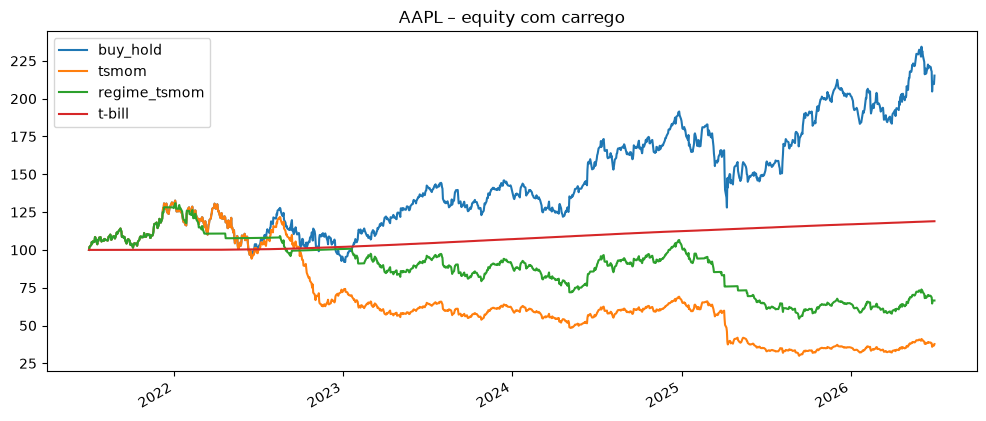

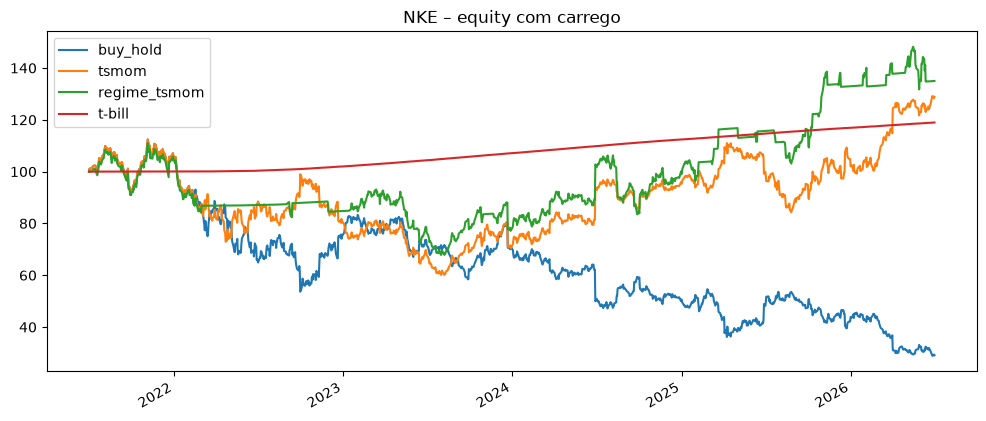

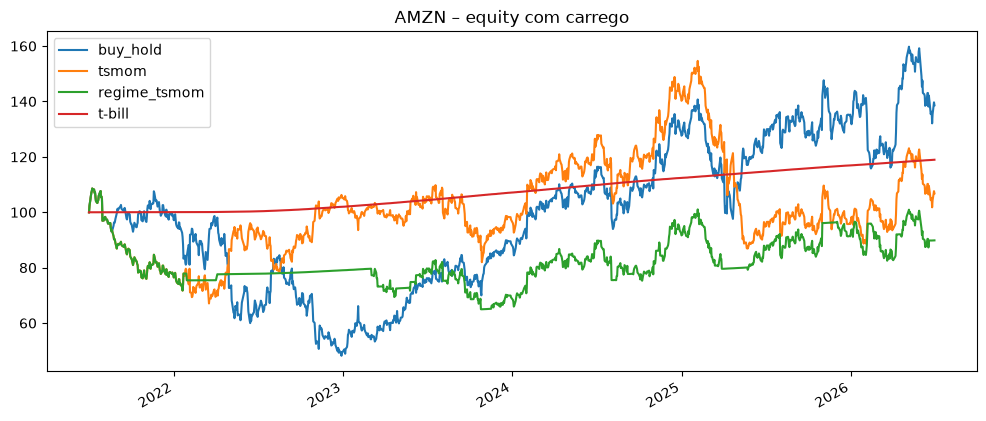

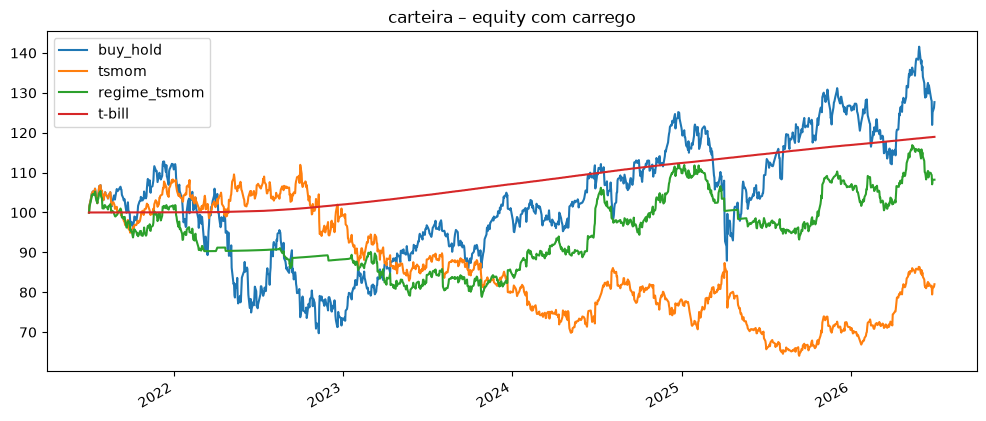

In [8]:
def curva(strat):
    r = pd.Series(strat.analyzers.ret_diario.get_analysis())
    r.index = pd.to_datetime(r.index)
    return 100 * (1 + r).cumprod()


for ativo in tickers + ["carteira"]:
    curvas = pd.DataFrame({nome: curva(resultados[(ativo, nome)][1]) for nome in estrategias})
    curvas["t-bill"] = 100 * (1 + rf_dia.reindex(curvas.index).fillna(0)).cumprod()
    curvas.plot(figsize=(12, 5), title=f"{ativo} – equity com carrego")
    plt.show()

In [9]:
tempo = pd.DataFrame({
    t: {
        "Alta vol – treino (%)": 100 * (regimes[t]["xi"].loc[:train_end] >= 0.5).mean(),
        "Alta vol – teste (%)": 100 * (regimes[t]["xi"].loc[test_start:] >= 0.5).mean(),
        "Trocas de regime – teste": int(((regimes[t]["xi"].loc[test_start:] >= 0.5).astype(int).diff().abs()).sum()),
    }
    for t in tickers
}).T.round(1)
display(tempo)

# % de dias em alta vol por janela de reestimação (jul → jun)
def rotulo_janela(idx):
    ano = (idx - pd.DateOffset(months=6)).year   # jul/2021–jun/2022 → 2021
    return [f"jul/{a} – jun/{a + 1}" for a in ano]

alta_por_janela = pd.DataFrame({
    t: 100 * (regimes[t]["xi"].loc[test_start:] >= 0.5)
             .groupby(rotulo_janela(regimes[t].loc[test_start:].index)).mean()
    for t in tickers
}).round(1)
alta_por_janela.index.name = "Janela"
display(alta_por_janela)

,Alta vol – treino (%),Alta vol – teste (%),Trocas de regime – teste
AAPL,50.3,25.7,63.0
NKE,20.8,38.7,66.0
AMZN,38.0,36.5,67.0


,AAPL,NKE,AMZN
Janela,,,
jul/2021 – jun/2022,42.1,37.7,43.3
jul/2022 – jun/2023,52.6,54.2,84.5
jul/2023 – jun/2024,3.6,6.0,12.4
jul/2024 – jun/2025,25.2,36.8,26.4
jul/2025 – jun/2026,4.8,58.6,15.9
